# Notebook 3: Resultater 

In [30]:
# Importerer nødvendige libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from openpyxl.styles import Alignment

In [2]:
# Leser inn resulatetene fra den logistiske regresjonsmodellen og LLM-en
lr_df = pd.read_csv('resultater_lr.csv')
llm_df = pd.read_csv('llm_test.csv')

# Kobler svarene sammen via klage-ID slik at begge resultatene står i samme tabell
resultater_df = lr_df.merge(llm_df[['Complaint ID', 'svar_llm']], on='Complaint ID')

In [3]:
# Lager en alfabetisk sortert liste over alle unike klagekategorier
kategorier = sorted(resultater_df['Issue'].unique())

# Baseline som alltid predikerer den største kategorien i treningssettet og fungerer som referanse for modellene
resultater_df['baseline'] = 'Problem with a purchase shown on your statement'

In [18]:
# Lager en ordbok som kobler navnet på hver metode til kolonnen som inneholder prediksjonene
metoder = {
    'Baseline': 'baseline',
    'Logistisk regresjon': 'lr_pred',
    'LLM (prompt B)': 'svar_llm',
}

# Lager en tabell
# Beregner accuracy og makro-F1 for hver metode ved å sammneligne prediksjonene med de faktiske kategoriene
sammenligning_df = pd.DataFrame({
    navn: {
        'Accuracy': accuracy_score(resultater_df['Issue'], resultater_df[kolonne]),
        'Makro-F1': f1_score(resultater_df['Issue'], resultater_df[kolonne], average='macro', zero_division=0),
    }
    for navn, kolonne in metoder.items()
}).T.round(2) # Snur tabellen slik at hver metode blir en rad, og runder av til to desimaler

# Skriver ut sammenligningstabellen
print(sammenligning_df)

                     Accuracy  Makro-F1
Baseline                 0.26      0.06
Logistisk regresjon      0.71      0.69
LLM (prompt B)           0.72      0.72


In [5]:
# Lager en tabell som beregner F1 for hver kategori for begge modellene
f1_per_kategori_df = pd.DataFrame({
    'Logistisk regresjon': f1_score(resultater_df['Issue'], resultater_df['lr_pred'], labels=kategorier, average=None, zero_division=0),
    'LLM (variant B)': f1_score(resultater_df['Issue'], resultater_df['svar_llm'], labels=kategorier, average=None, zero_division=0),
}, index=kategorier).round(2) 

# Lager en ny kolonne som viser hvor mye bedre eller dårligere LLM-en er enn LR for hver kategori
f1_per_kategori_df['Forskjell'] = (f1_per_kategori_df['LLM (variant B)'] - f1_per_kategori_df['Logistisk regresjon']).round(2)

# Sorterer tabellen fra størst til minst forskjell, og skriver den ut
print(f1_per_kategori_df.sort_values('Forskjell', ascending=False))

                                                    Logistisk regresjon  \
Closing your account                                               0.68   
Advertising and marketing, including promotiona...                 0.61   
Getting a credit card                                              0.74   
Other features, terms, or problems                                 0.52   
Problem with a purchase shown on your statement                    0.84   
Fees or interest                                                   0.73   
Problem when making payments                                       0.73   

                                                    LLM (variant B)  Forskjell  
Closing your account                                           0.79       0.11  
Advertising and marketing, including promotiona...             0.68       0.07  
Getting a credit card                                          0.80       0.06  
Other features, terms, or problems                             0.54       0

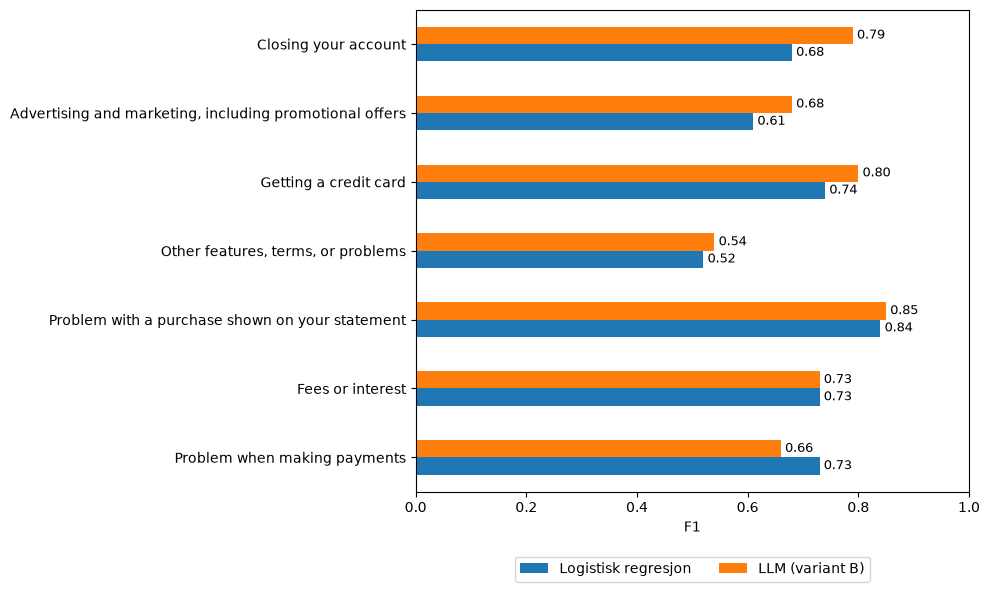

In [24]:
# Lager et liggende søylediagram sortert etter forskjellen mellom LLM og LR
ax = f1_per_kategori_df.sort_values('Forskjell')[['Logistisk regresjon', 'LLM (variant B)']].plot(kind='barh', figsize=(10, 6))

# Viser F1-verdien ved enden av hver søyle
for søyler in ax.containers:
    #ax.bar_label(søyler, labels=[f'{v:.2f}'.replace('.', ',') for v in søyler.datavalues], padding=3, fontsize=9)
    ax.bar_label(søyler, fmt='%.2f', padding=3, fontsize=9)
    
# Setter aksetekst, skala og tittel
plt.xlabel('F1')
plt.xlim(0, 1)

# Flytter forklaringen ned i hjørnet så den ikke dekker søylene
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)

# Justerer marginene, lagrer og viser figuren
plt.tight_layout()
plt.savefig('f1_per_kategori.png', dpi=200)
plt.show()

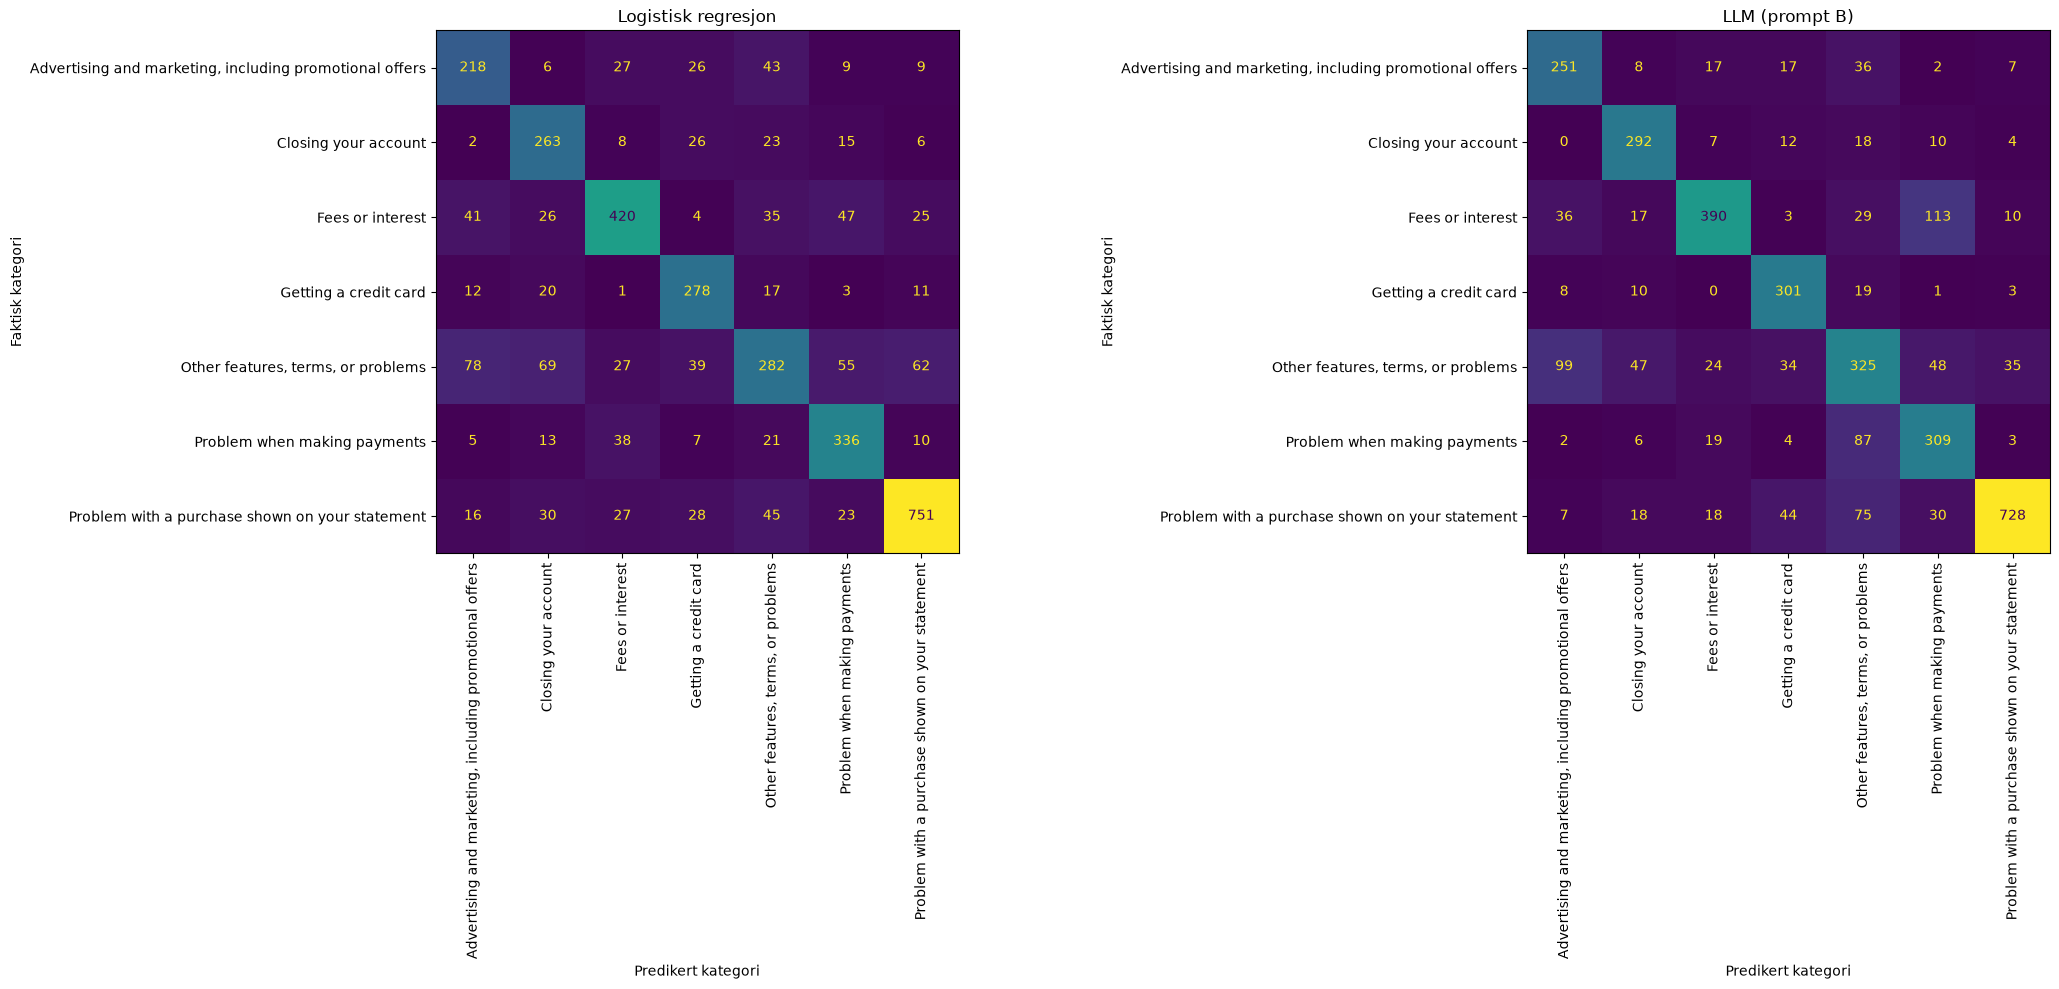

In [25]:
# Lager en figur med forvekslingsmatrisene for LR og LLM
fig, axes = plt.subplots(1, 2, figsize=(22, 10))

for ax, (navn, kolonne) in zip(axes, [('Logistisk regresjon', 'lr_pred'), ('LLM (prompt B)', 'svar_llm')]):
    ConfusionMatrixDisplay.from_predictions(
        resultater_df['Issue'], resultater_df[kolonne], labels=kategorier,
        xticks_rotation=90, ax=ax, colorbar=False
    )
    ax.set_title(navn)
    ax.set_xlabel('Predikert kategori')
    ax.set_ylabel('Faktisk kategori')

plt.tight_layout()
plt.savefig('forvekslingsmatriser.png', bbox_inches='tight', dpi=200)
plt.show()

In [8]:
# Lager en krysstabell som viser hvor ofte modellene tar riktig og galt på de samme klagene
resultater_df['lr_riktig'] = resultater_df['lr_pred'] == resultater_df['Issue']
resultater_df['llm_riktig'] = resultater_df['svar_llm'] == resultater_df['Issue']

print(pd.crosstab(resultater_df['lr_riktig'], resultater_df['llm_riktig'], rownames=['LR riktig'], colnames=['LLM riktig']))

LLM riktig  False  True 
LR riktig               
False         646    389
True          341   2207


In [27]:
# Skriver ut tilfeldige eksempler med fasit, begge prediksjonene og starten av klageteksten
def vis_eksempler(tabell_df, antall):
    for _, rad in tabell_df.sample(antall, random_state=1).iterrows():
        print('Fasit:', rad['Issue'])
        print('Logistisk regresjon:', rad['lr_pred'])
        print('LLM:', rad['svar_llm'])
        print(rad['Consumer complaint narrative'][:800])   
        print('-' * 80)

# Henter ut klagene der bare én av modellene predikerte riktig, og viser fem eksempler
ulike_utfall_df = resultater_df[resultater_df['lr_riktig'] != resultater_df['llm_riktig']]
vis_eksempler(ulike_utfall_df, 5)

Fasit: Other features, terms, or problems
Logistisk regresjon: Problem when making payments
LLM: Other features, terms, or problems
Around XX/XX/XXXX and XX/XX/XXXX, due to some unexpected medical bills in diagnosing my daughter for a XXXX condition, I got behind in paying my bills. After successfully making arrangements for the medical related bills, I tried to do the same with Bank of America. 
Ironically, in part of an article originally published by XXXX, ( http : XXXX ) it states : Bank of America was among the eight large U.S. banks ( nine if you count XXXX XXXX , now part of BoA ) to receive the Treasury Department 's initial round of capital investments in the fall of XX/XX/XXXX -- money described by Treasury officials not as a bailout, but rather as funds to help bolster " healthy '' banks in tough times. 

This large cooperation received funds to help them in tough times, however, I as a previously healthy co
-------------------------------------------------------------------

In [28]:
# Henter ut klagene der både LR og LLM-en predikerte feil, og viser ti eksempler
begge_feil_df = resultater_df[~resultater_df['lr_riktig'] & ~resultater_df['llm_riktig']]
vis_eksempler(begge_feil_df, 10)

Fasit: Getting a credit card
Logistisk regresjon: Closing your account
LLM: Closing your account
They XXXX 's said they closed my card out now saying no but basically holding me to things I never ordered received n refusing to close the account I 'm now getting threatening letters to take action vs a  identity theft victim XXXX which is wrong.i do n't owe XXXX 's n they sent me letters stating so I do n't know what their new position is but it 's not gon na fly vs me
--------------------------------------------------------------------------------
Fasit: Advertising and marketing, including promotional offers
Logistisk regresjon: Fees or interest
LLM: Fees or interest
I obtained the credit card  XXXX  through a furniture store and when signing up I was informed that I would be getting no interest charges for the first year, after which interest would start being charged on a monthly basis for the amount that remained. When I received the bill for the  XXXX  month, in  XXXX   2017 , the 

In [12]:
# Lager en tilfeldigshetsgenerator med fast startverdi slik at resultatet kan gjenskapes
rng = np.random.default_rng(1)

# Tom liste som fylles med forskjellen i makro-F1 fra hver trekning
forskjeller = []

# Gjentar løkken 1000 ganger
for _ in range(1000):
    # Trekker like mange klager som i testettet, med tilbakelegging
    utvalg = rng.integers(0, len(resultater_df), len(resultater_df))   
    utvalg_df = resultater_df.iloc[utvalg]
    
    # Lagrer forskjellen i makro-F1 mellom LLM-en og LR for dette utvalget
    forskjeller.append(
        f1_score(utvalg_df['Issue'], utvalg_df['svar_llm'], average='macro', zero_division=0)
        - f1_score(utvalg_df['Issue'], utvalg_df['lr_pred'], average='macro', zero_division=0)
)

# Beregner 95 % konfidensintervall og andelen trekninger der LLM-en ikke var bedre enn LR
forskjeller = np.array(forskjeller)
print('95 % konfidensintervall for forskjellen i makro-F1:', np.percentile(forskjeller, [2.5, 97.5]).round(3))
print('Andel trekninger der LLM ikke var bedre:', (forskjeller <= 0).mean())

95 % konfidensintervall for forskjellen i makro-F1: [0.01  0.041]
Andel trekninger der LLM ikke var bedre: 0.0


In [13]:
# Finner de fem vanligste forvekslingene for hver modell
for navn, kolonne in [('Logistisk regresjon', 'lr_pred'), ('LLM (variant B)', 'svar_llm')]:
    # Henter ut klagene der modellen predikerte feil kategori
    feil_df = resultater_df[resultater_df[kolonne] != resultater_df['Issue']]

    # Teller hvor ofte hver kombinasjon av faktisk og predikert kategori forekommer, og beholder de fem vanligste
    forvekslinger = feil_df.groupby(['Issue', kolonne]).size().sort_values(ascending=False).head(5)

    print(navn)
    print(forvekslinger)
    print()

Logistisk regresjon
Issue                               lr_pred                                                
Other features, terms, or problems  Advertising and marketing, including promotional offers    78
                                    Closing your account                                       69
                                    Problem with a purchase shown on your statement            62
                                    Problem when making payments                               55
Fees or interest                    Problem when making payments                               47
dtype: int64

LLM (variant B)
Issue                                            svar_llm                                               
Fees or interest                                 Problem when making payments                               113
Other features, terms, or problems               Advertising and marketing, including promotional offers     99
Problem when making payments           

In [14]:
# Henter ut klagene der både LR og LLM-en predikerte feil
begge_feil_df = resultater_df[~resultater_df['lr_riktig'] & ~resultater_df['llm_riktig']].copy()

# Markerer om de to modellene valgte den samme gale kategorien
begge_feil_df['samme_feil'] = begge_feil_df['lr_pred'] == begge_feil_df['svar_llm']

# Teller hvor ofte modellene tok feil på samme måte og på ulik måte
print(begge_feil_df['samme_feil'].value_counts())

samme_feil
True     459
False    187
Name: count, dtype: int64


In [38]:
# Teller antall ord i hver klage
resultater_df['antall_ord'] = resultater_df['Consumer complaint narrative'].str.split().str.len()

# Deler klagene i fire like store grupper etter lengde
resultater_df['lengdegruppe'] = pd.qcut(resultater_df['antall_ord'].rank(method='first'), 4,
                                        labels=['Korteste 25 %', '25–50 %', '50–75 %', 'Lengste 25 %'])

# Beregner makro-F1 for hver modell i hver lengdegruppe
makro_f1_lengde_df = resultater_df.groupby('lengdegruppe', observed=True).apply(
    lambda gruppe: pd.Series({
        'LR': f1_score(gruppe['Issue'], gruppe['lr_pred'], average='macro', zero_division=0),
        'LLM': f1_score(gruppe['Issue'], gruppe['svar_llm'], average='macro', zero_division=0),
    })
).round(2)

print(makro_f1_lengde_df)

                 LR   LLM
lengdegruppe             
Korteste 25 %  0.71  0.72
25–50 %        0.70  0.75
50–75 %        0.67  0.69
Lengste 25 %   0.66  0.71


In [41]:
# Teller antall ord i hver klage
resultater_df['antall_ord'] = resultater_df['Consumer complaint narrative'].str.split().str.len()

# Deler klagene i fire like store grupper etter lengde
resultater_df['lengdegruppe'] = pd.qcut(resultater_df['antall_ord'].rank(method='first'), 4,
                                        labels=['Korteste 25 %', '25–50 %', '50–75 %', 'Lengste 25 %'])

# Finner minste og største antall ord, og antall klager i hver kvartil
ord_per_gruppe_df = resultater_df.groupby('lengdegruppe', observed=True)['antall_ord'].agg(
    min_ord='min', maks_ord='max', antall_klager='count'
)

# Beregner makro-F1 for hver modell 
makro_f1_lengde_df = resultater_df.groupby('lengdegruppe', observed=True).apply(
    lambda gruppe: pd.Series({
        'LR': f1_score(gruppe['Issue'], gruppe['lr_pred'], average='macro', zero_division=0),
        'LLM': f1_score(gruppe['Issue'], gruppe['svar_llm'], average='macro', zero_division=0),
    })
).round(2)

print(ord_per_gruppe_df.join(makro_f1_lengde_df))

               min_ord  maks_ord  antall_klager    LR   LLM
lengdegruppe                                               
Korteste 25 %        4       106            896  0.71  0.72
25–50 %            106       186            896  0.70  0.75
50–75 %            186       308            895  0.67  0.69
Lengste 25 %       308      5735            896  0.66  0.71


In [33]:
# Finner korteste og lengste klage i testsettet, målt i antall ord
print('Korteste klage:', resultater_df['antall_ord'].min(), 'ord')
print('Lengste klage:', resultater_df['antall_ord'].max(), 'ord')

Korteste klage: 4 ord
Lengste klage: 5735 ord


In [31]:
# Trekker 50 tilfeldige klager der begge modellene tok feil, med kolonnene som trengs for manuell gjennomgang
feilanalyse_df = begge_feil_df.sample(50, random_state=1)[
    ['Complaint ID', 'Issue', 'lr_pred', 'svar_llm', 'Consumer complaint narrative']
].copy()

# Legger til tomme kolonner for å kategorisere og kommentere hver feil manuelt
feilanalyse_df['feiltype'] = ''
feilanalyse_df['kommentar'] = ''

# Lagrer utvalget som en Excel-fil med ryddig formatering for manuell gjennomgang
with pd.ExcelWriter('feilanalyse_utvalg.xlsx', engine='openpyxl') as writer:
    feilanalyse_df.to_excel(writer, index=False, sheet_name='Feilanalyse')
    ark = writer.sheets['Feilanalyse']

    # Setter kolonnebredder: ID, fasit, LR, LLM, klagetekst, feiltype, kommentar
    for kolonne, bredde in zip('ABCDEFG', [12, 28, 28, 28, 90, 22, 40]):
        ark.column_dimensions[kolonne].width = bredde

    # Bryter teksten i alle celler og plasserer den øverst i cellen
    for rad in ark.iter_rows():
        for celle in rad:
            celle.alignment = Alignment(wrap_text=True, vertical='top')

    # Fryser overskriftsraden så den alltid er synlig når du blar
    ark.freeze_panes = 'A2'

In [17]:
  print("Ugyldige LLM-svar:", (resultater_df['svar_llm'] == 'UGYLDIG').sum())

Ugyldige LLM-svar: 0
